# Unsupervised Learning: Trade & Ahead

## Problem Statement

### Context

The stock market has consistently proven to be a good place to invest in and save for the future. There are a lot of compelling reasons to invest in stocks. It can help in fighting inflation, create wealth, and also provides some tax benefits. Good steady returns on investments over a long period of time can also grow a lot more than seems possible. Also, thanks to the power of compound interest, the earlier one starts investing, the larger the corpus one can have for retirement. Overall, investing in stocks can help meet life's financial aspirations.

It is important to maintain a diversified portfolio when investing in stocks in order to maximise earnings under any market condition. Having a diversified portfolio tends to yield higher returns and face lower risk by tempering potential losses when the market is down. It is often easy to get lost in a sea of financial metrics to analyze while determining the worth of a stock, and doing the same for a multitude of stocks to identify the right picks for an individual can be a tedious task. By doing a cluster analysis, one can identify stocks that exhibit similar characteristics and ones which exhibit minimum correlation. This will help investors better analyze stocks across different market segments and help protect against risks that could make the portfolio vulnerable to losses.


### Objective

Trade&Ahead is a financial consultancy firm who provide their customers with personalized investment strategies. They have hired you as a Data Scientist and provided you with data comprising stock price and some financial indicators for a few companies listed under the New York Stock Exchange. They have assigned you the tasks of analyzing the data, grouping the stocks based on the attributes provided, and sharing insights about the characteristics of each group.

### Data Dictionary

- Ticker Symbol: An abbreviation used to uniquely identify publicly traded shares of a particular stock on a particular stock market
- Company: Name of the company
- GICS Sector: The specific economic sector assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- GICS Sub Industry: The specific sub-industry group assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- Current Price: Current stock price in dollars
- Price Change: Percentage change in the stock price in 13 weeks
- Volatility: Standard deviation of the stock price over the past 13 weeks
- ROE: A measure of financial performance calculated by dividing net income by shareholders' equity (shareholders' equity is equal to a company's assets minus its debt)
- Cash Ratio: The ratio of a  company's total reserves of cash and cash equivalents to its total current liabilities
- Net Cash Flow: The difference between a company's cash inflows and outflows (in dollars)
- Net Income: Revenues minus expenses, interest, and taxes (in dollars)
- Earnings Per Share: Company's net profit divided by the number of common shares it has outstanding (in dollars)
- Estimated Shares Outstanding: Company's stock currently held by all its shareholders
- P/E Ratio: Ratio of the company's current stock price to the earnings per share
- P/B Ratio: Ratio of the company's stock price per share by its book value per share (book value of a company is the net difference between that company's total assets and total liabilities)

## Importing necessary libraries and data

In [38]:

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to compute distances
from scipy.spatial.distance import pdist

# to perform hierarchical clustering, compute cophenetic correlation, and create dendrograms
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To supress warnings
import warnings

warnings.filterwarnings("ignore")

In [2]:
#FUNCTIONS
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [4]:
df=pd.read_csv('/content/drive/MyDrive/GREAT LEARNING/6. UNSUPERVISED LEARNING/Proyect/stock_data.csv')

## Data Overview

- Observations
- Sanity checks

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticker Symbol                 340 non-null    object 
 1   Security                      340 non-null    object 
 2   GICS Sector                   340 non-null    object 
 3   GICS Sub Industry             340 non-null    object 
 4   Current Price                 340 non-null    float64
 5   Price Change                  340 non-null    float64
 6   Volatility                    340 non-null    float64
 7   ROE                           340 non-null    int64  
 8   Cash Ratio                    340 non-null    int64  
 9   Net Cash Flow                 340 non-null    int64  
 10  Net Income                    340 non-null    int64  
 11  Earnings Per Share            340 non-null    float64
 12  Estimated Shares Outstanding  340 non-null    float64
 13  P/E R

In [ ]:
df.describe()


,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio
count,340.000,340.000,340.000,340.000,340.000,340.000,340.000,340.000,340.000,340.000,340.000
mean,80.862,4.078,1.526,39.597,70.024,55537620.588,1494384602.941,2.777,577028337.754,32.613,-1.718
std,98.055,12.006,0.592,96.548,90.421,1946365312.176,3940150279.328,6.588,845849595.418,44.349,13.967
min,4.500,-47.130,0.733,1.000,0.000,-11208000000.000,-23528000000.000,-61.200,27672156.860,2.935,-76.119
25%,38.555,-0.939,1.135,9.750,18.000,-193906500.000,352301250.000,1.558,158848216.100,15.045,-4.352
50%,59.705,4.820,1.386,15.000,47.000,2098000.000,707336000.000,2.895,309675137.800,20.820,-1.067
75%,92.880,10.695,1.696,27.000,99.000,169810750.000,1899000000.000,4.620,573117457.325,31.765,3.917
max,1274.950,55.052,4.580,917.000,958.000,20764000000.000,24442000000.000,50.090,6159292035.000,528.039,129.065


## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What does the distribution of stock prices look like?
2. The stocks of which economic sector have seen the maximum price increase on average?
3. How are the different variables correlated with each other?
4. Cash ratio provides a measure of a company's ability to cover its short-term obligations using only cash and cash equivalents. How does the average cash ratio vary across economic sectors?
5. P/E ratios can help determine the relative value of a company's shares as they signify the amount of money an investor is willing to invest in a single share of a company per dollar of its earnings. How does the P/E ratio vary, on average, across economic sectors?

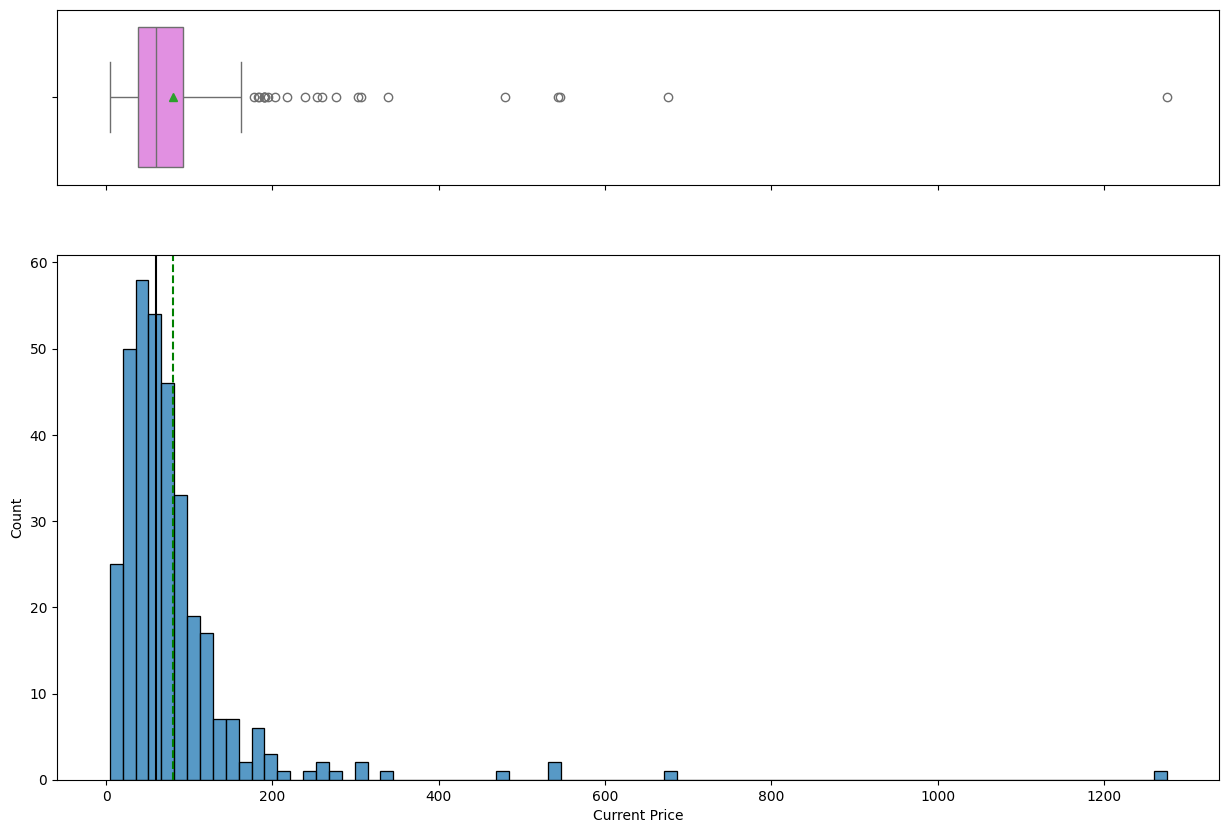

In [ ]:
histogram_boxplot(df, 'Current Price')

Stock prices have a right skewed distribution. Having its mean around 80. We can see some outliers with values around 600 and 1200 dollars

In [ ]:
df.groupby('GICS Sector')['Price Change'].mean().sort_values(ascending=False)

,Price Change
GICS Sector,
Health Care,9.586
Consumer Staples,8.685
Information Technology,7.217
Telecommunications Services,6.957
Real Estate,6.206
Consumer Discretionary,5.846
Materials,5.590
Financials,3.865
Industrials,2.833


The Sector with the most price increase is Healthcare with an average of 9.5% price Increase, followed by COnsumer Staples and Information and Technology with an increase of 8.6% and 7.2% respectively

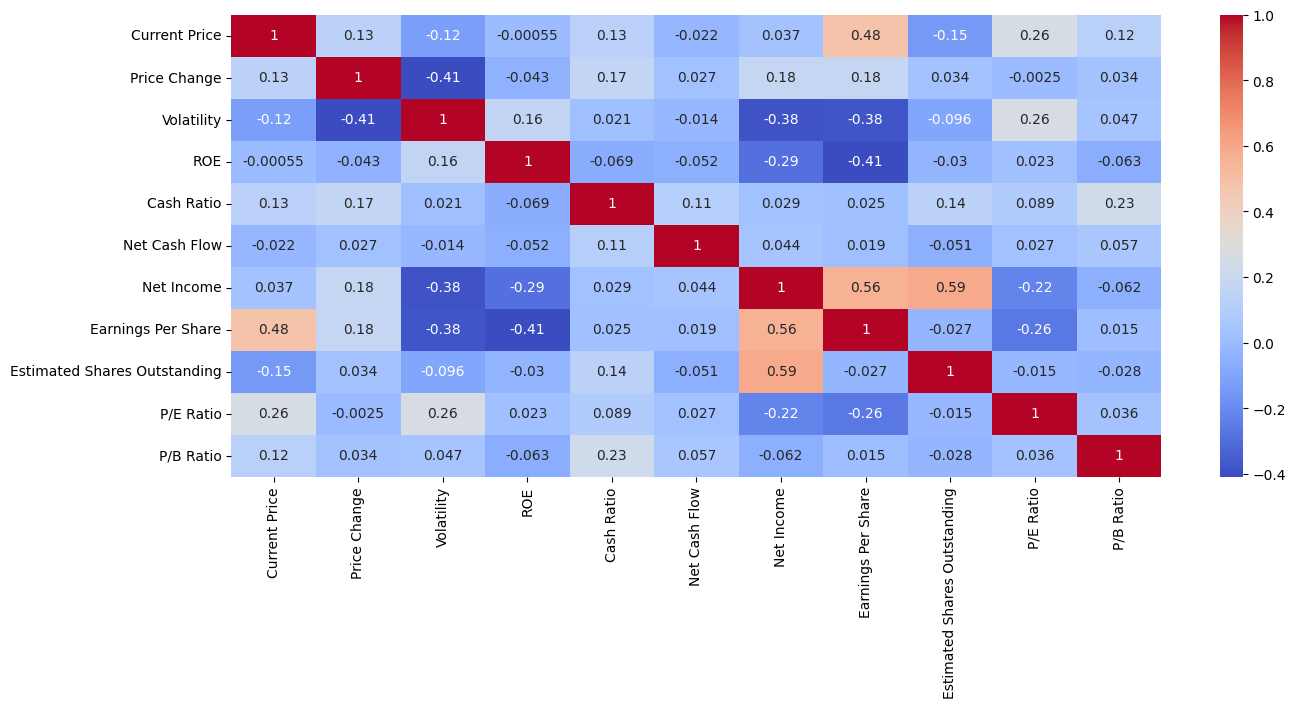

In [ ]:
corre = df.select_dtypes(include='number').corr()

plt.figure(figsize=(15, 6))
sns.heatmap(corre, annot=True, cmap='coolwarm')
plt.show()

We can see that the highest values of correaltion are 0.59 between Net income & Estimated Shares Outstanding, 0.56 between Net income & Earnings per share, -0.41 between ROE & Earnings per share, -0.41 between Volatility & Price Change  
and -0.38 between Volatility & Earnings per share

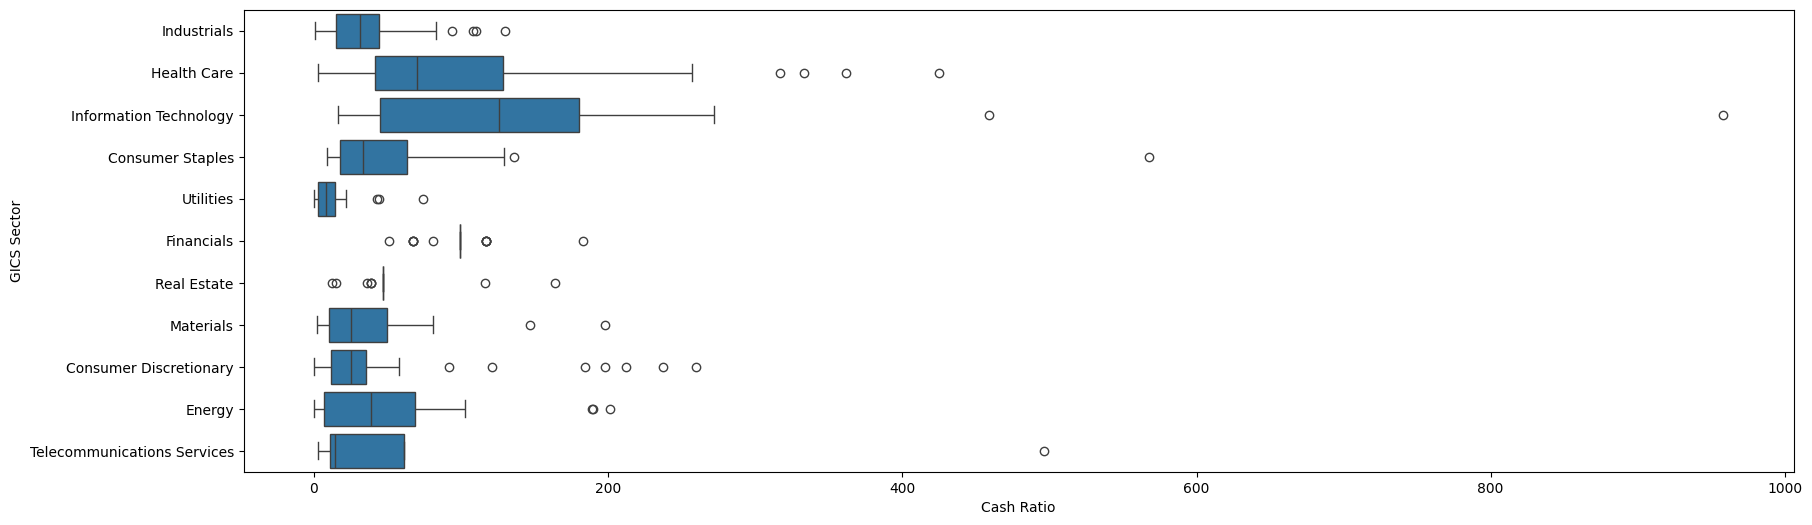

In [ ]:
plt.figure(figsize=(20, 6))
sns.boxplot(data=df, x='Cash Ratio',y='GICS Sector')
plt.show()

We can see that the Information and technology stocks have the highest Cash Ratio on average but also they have the highest volatolity. On the other hand, Utilitie stocks have the lowest Cash Ratio but also the lowest volatility. Health care is another sectro with a high volatility and a high mean Cash ratio.

The Financial and Real Estate stocks seem to have very little volatility. The boxplot of these sectros dont hace a body.

The rest of the sectors seem to have have a similar Cash Ratio distribution.

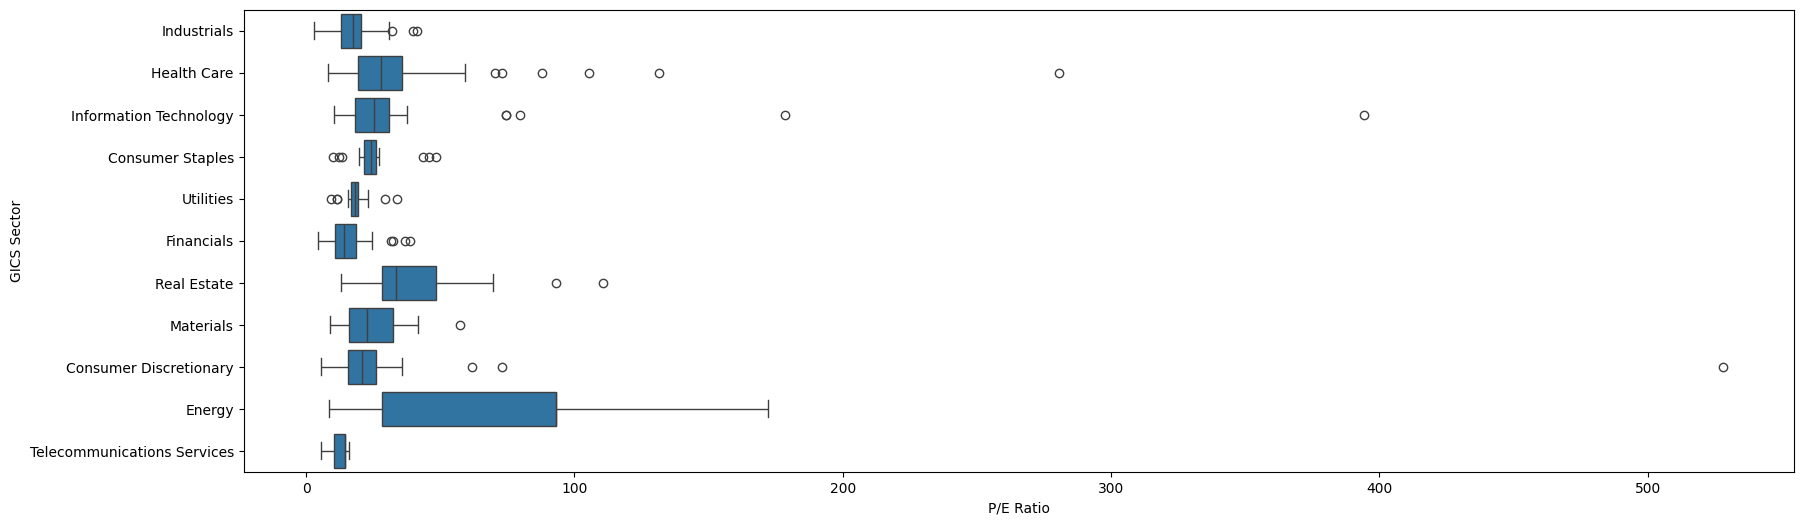

In [ ]:
plt.figure(figsize=(20, 6))
sns.boxplot(data=df, x='P/E Ratio',y='GICS Sector')
plt.show()

The most striking box in the graph is the Energy stocks, it has considerably more volatility in terms of P/E ratio than all the otrer sectors. The rest of the sectors seems to hace a similar P/E Ratio Distribution.

## Univariate

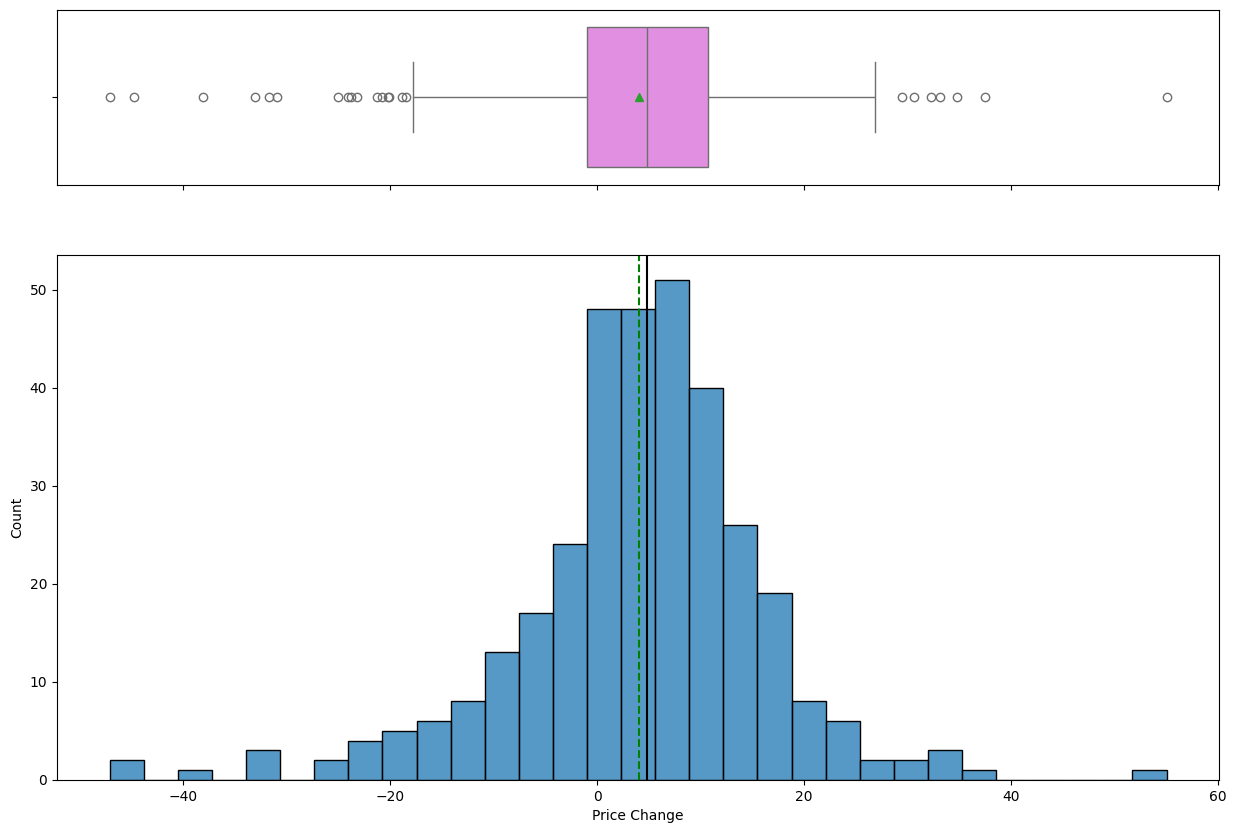

In [ ]:
histogram_boxplot(df, 'Price Change')

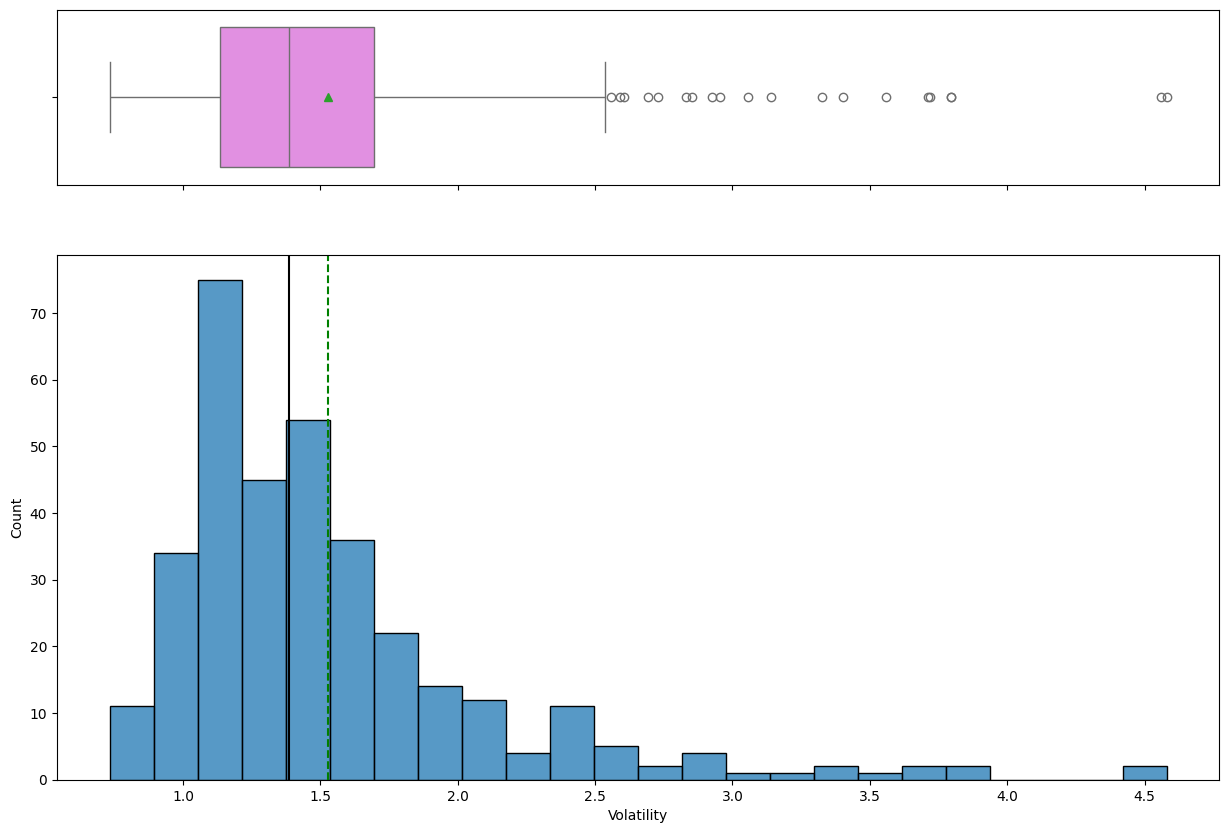

In [ ]:
histogram_boxplot(df, 'Volatility')

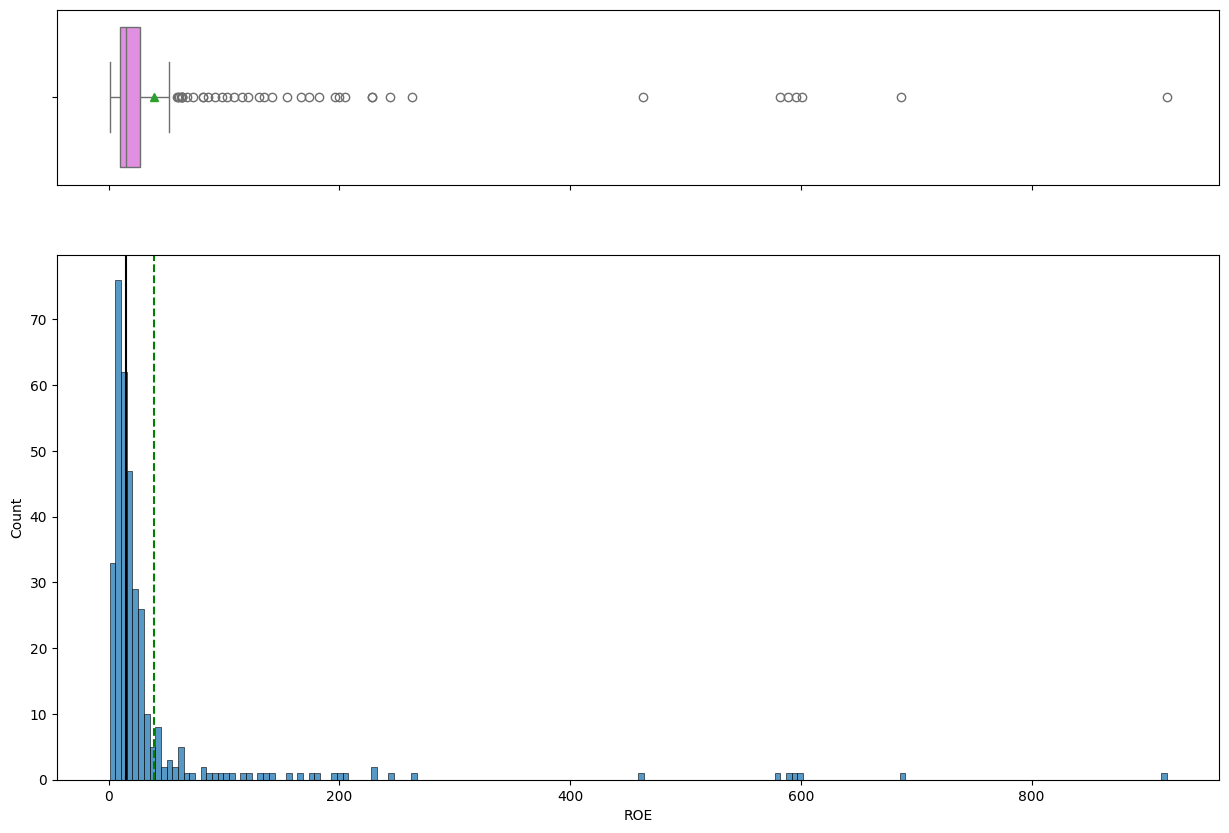

In [ ]:
histogram_boxplot(df, 'ROE')

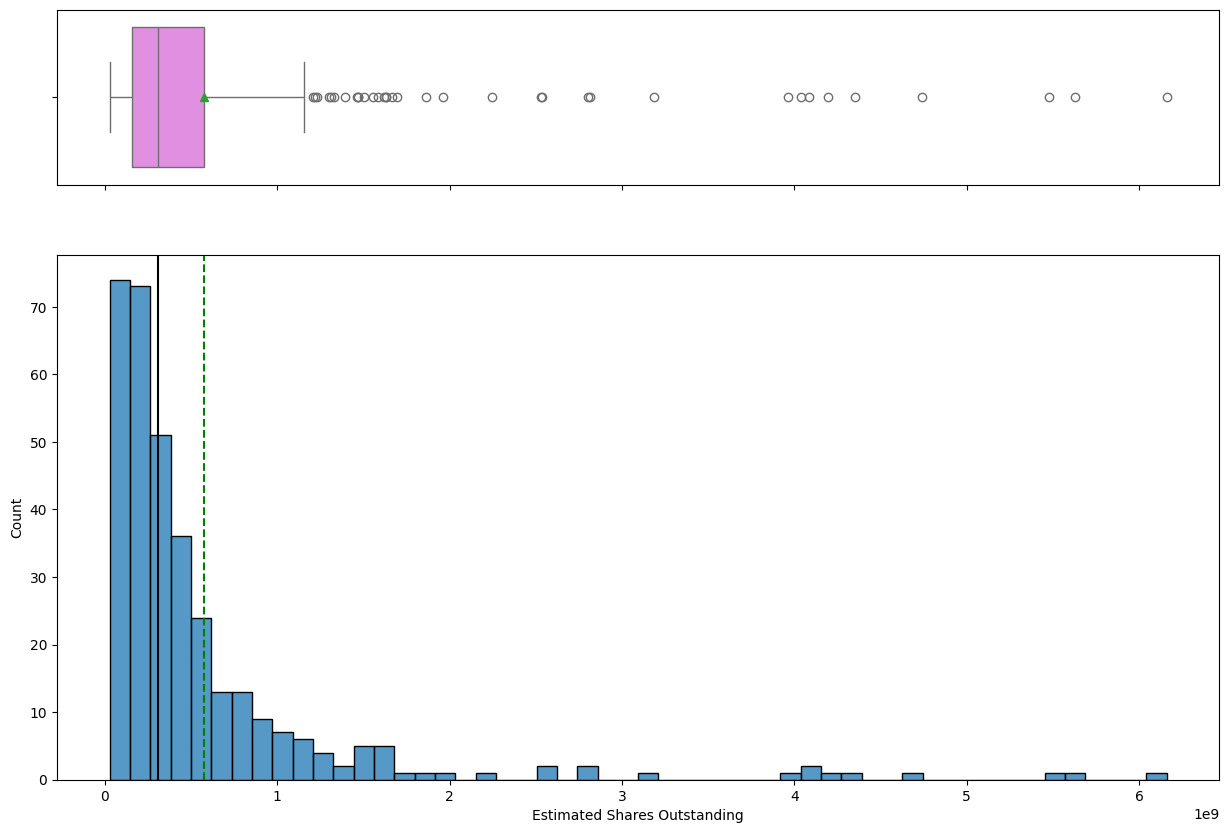

In [ ]:
histogram_boxplot(df, 'Estimated Shares Outstanding')

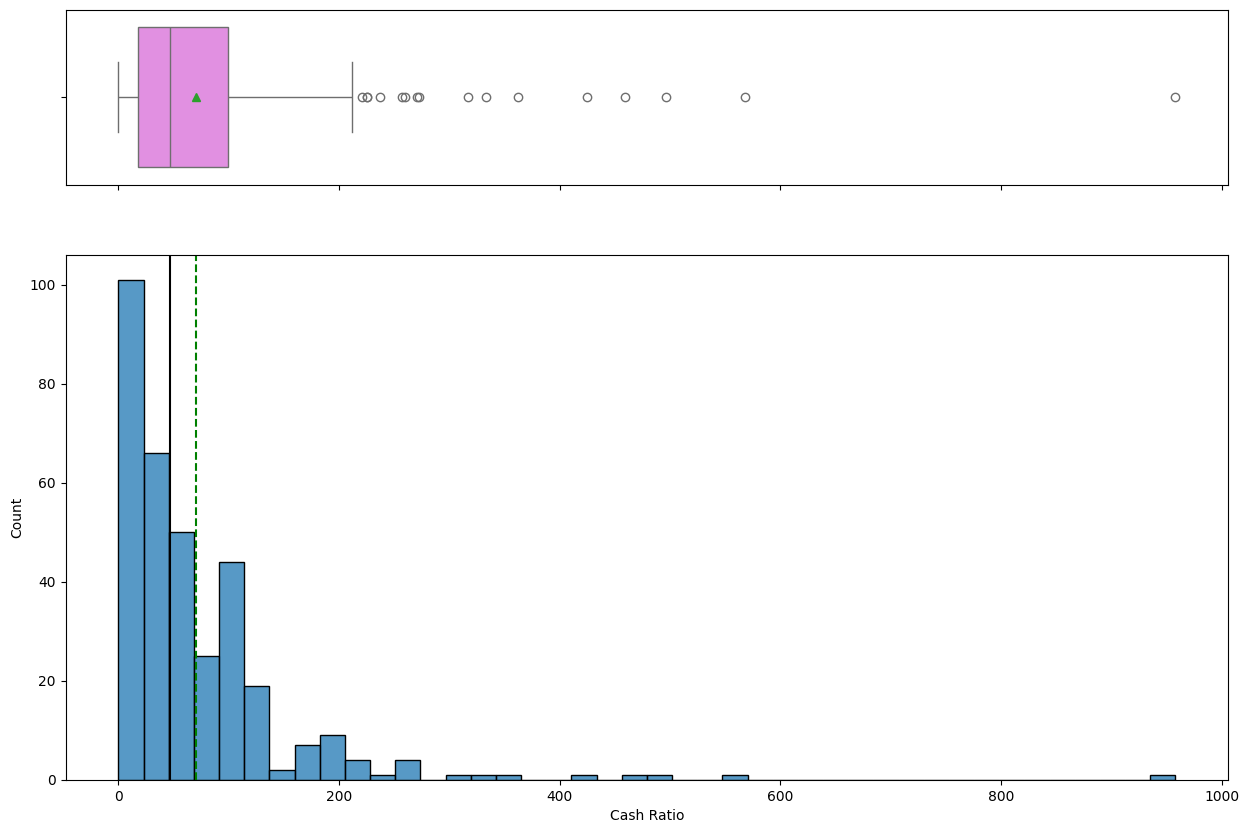

In [ ]:
histogram_boxplot(df, 'Cash Ratio')

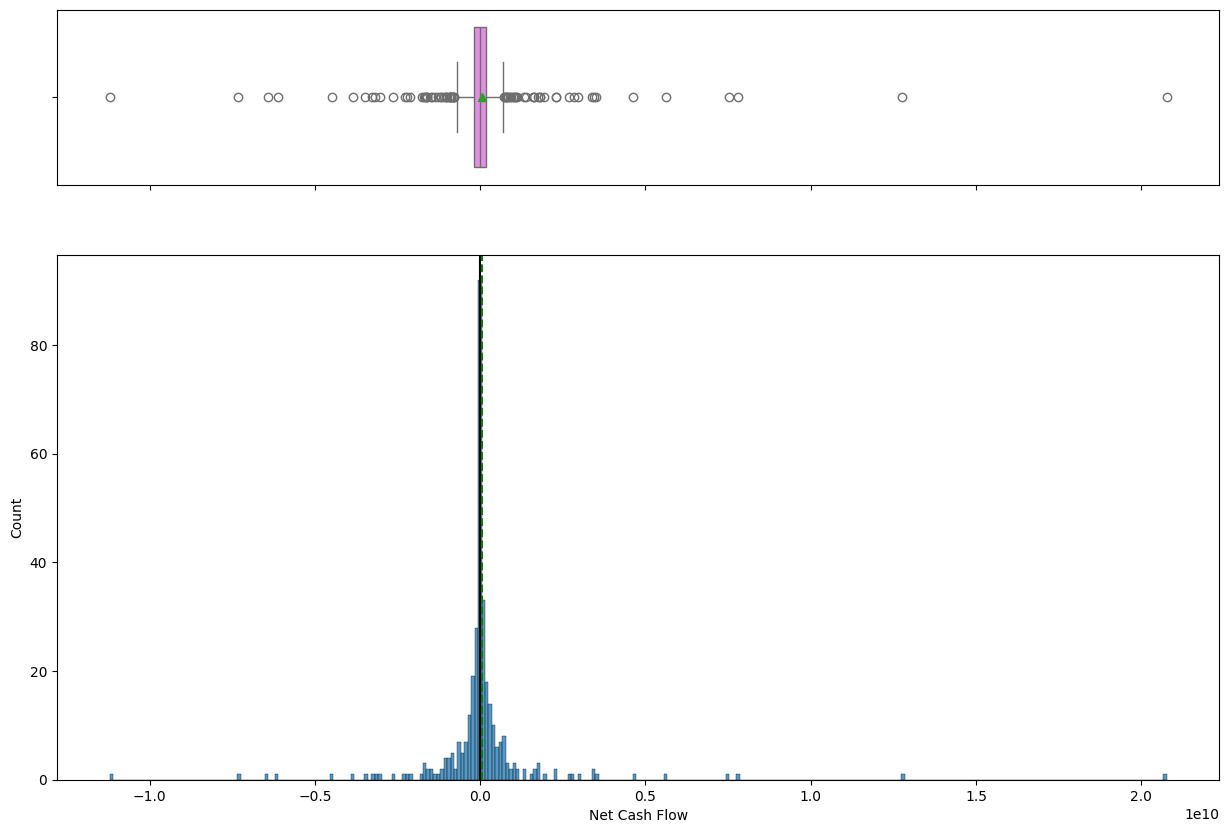

In [ ]:
histogram_boxplot(df, 'Net Cash Flow')

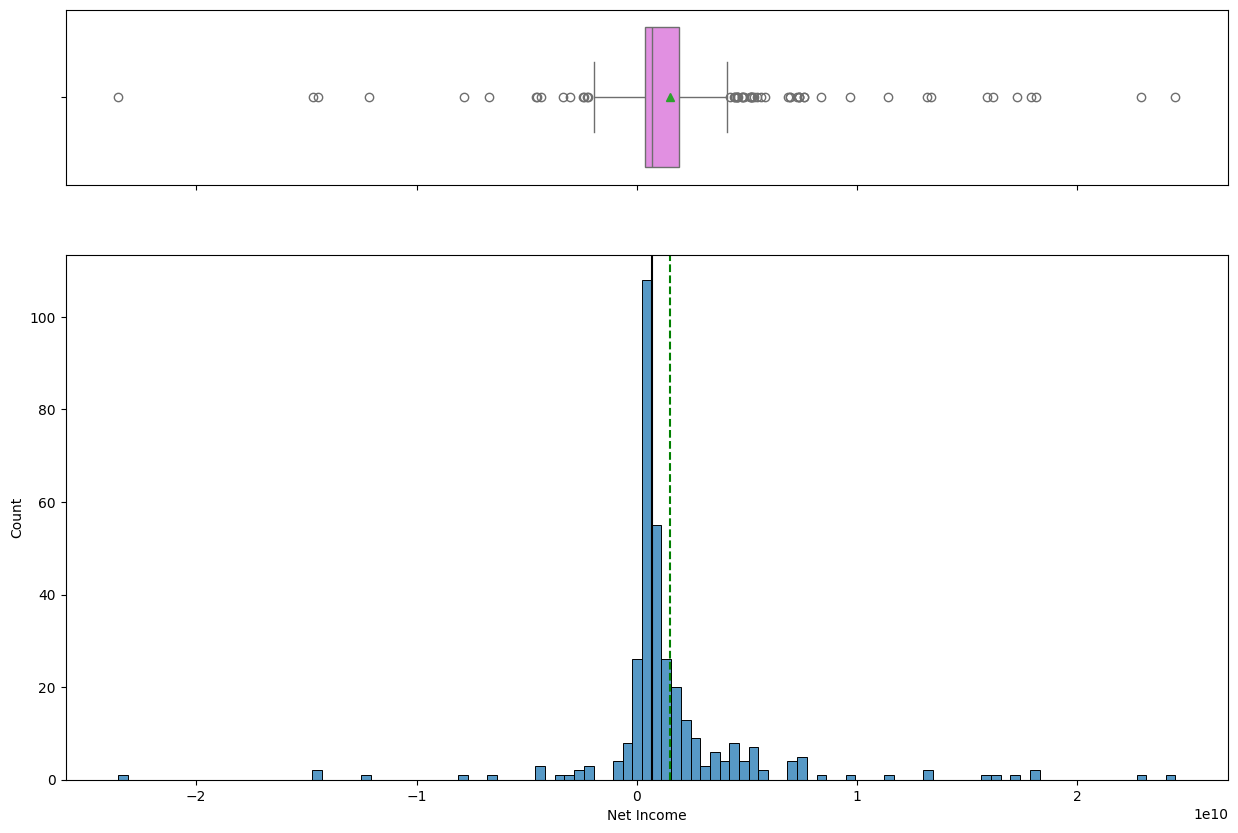

In [ ]:
histogram_boxplot(df, 'Net Income')

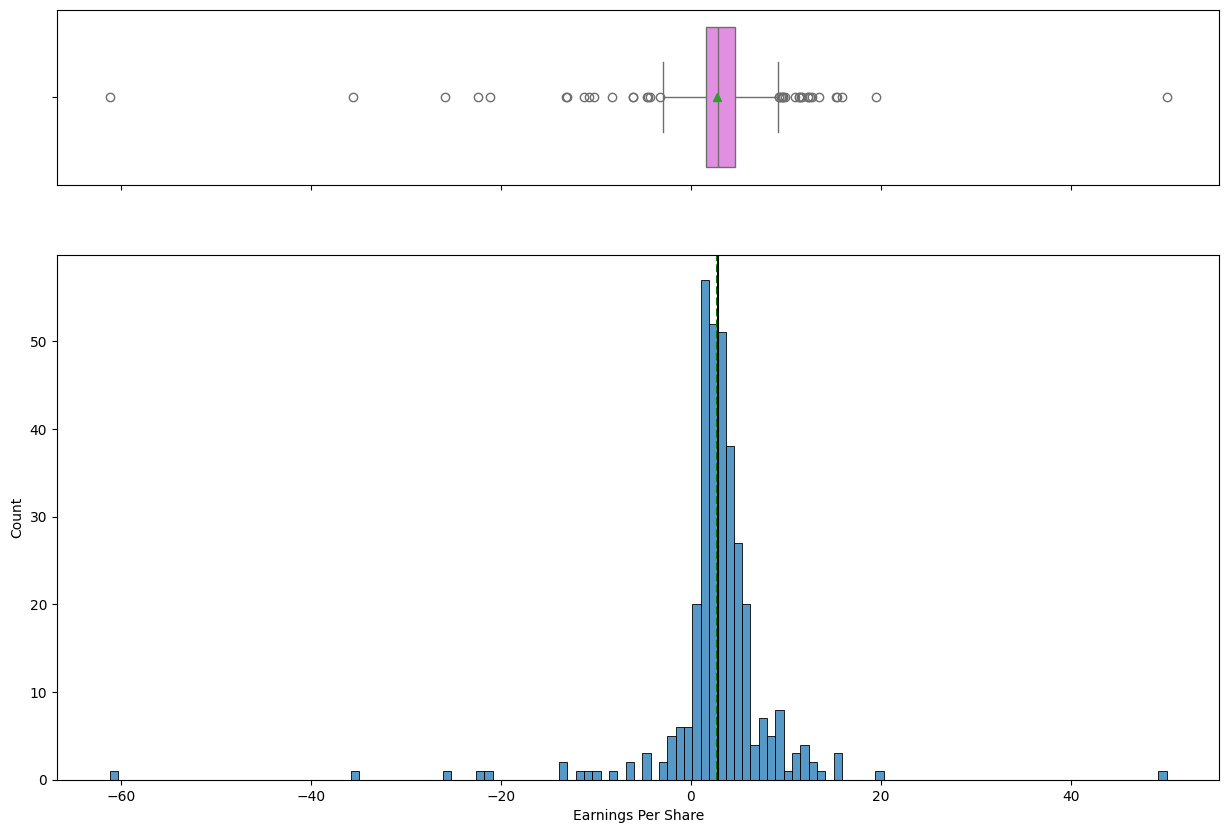

In [ ]:
histogram_boxplot(df, 'Earnings Per Share')

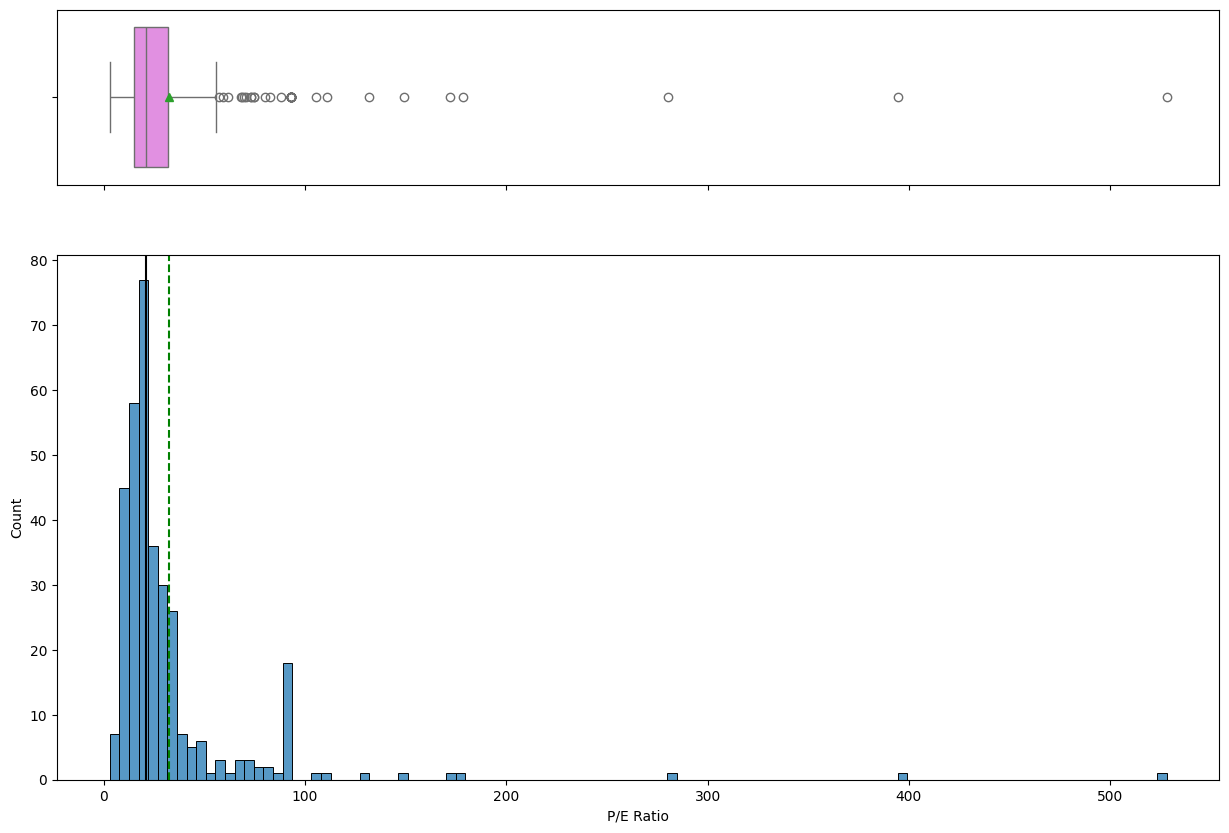

In [ ]:
histogram_boxplot(df, 'P/E Ratio')

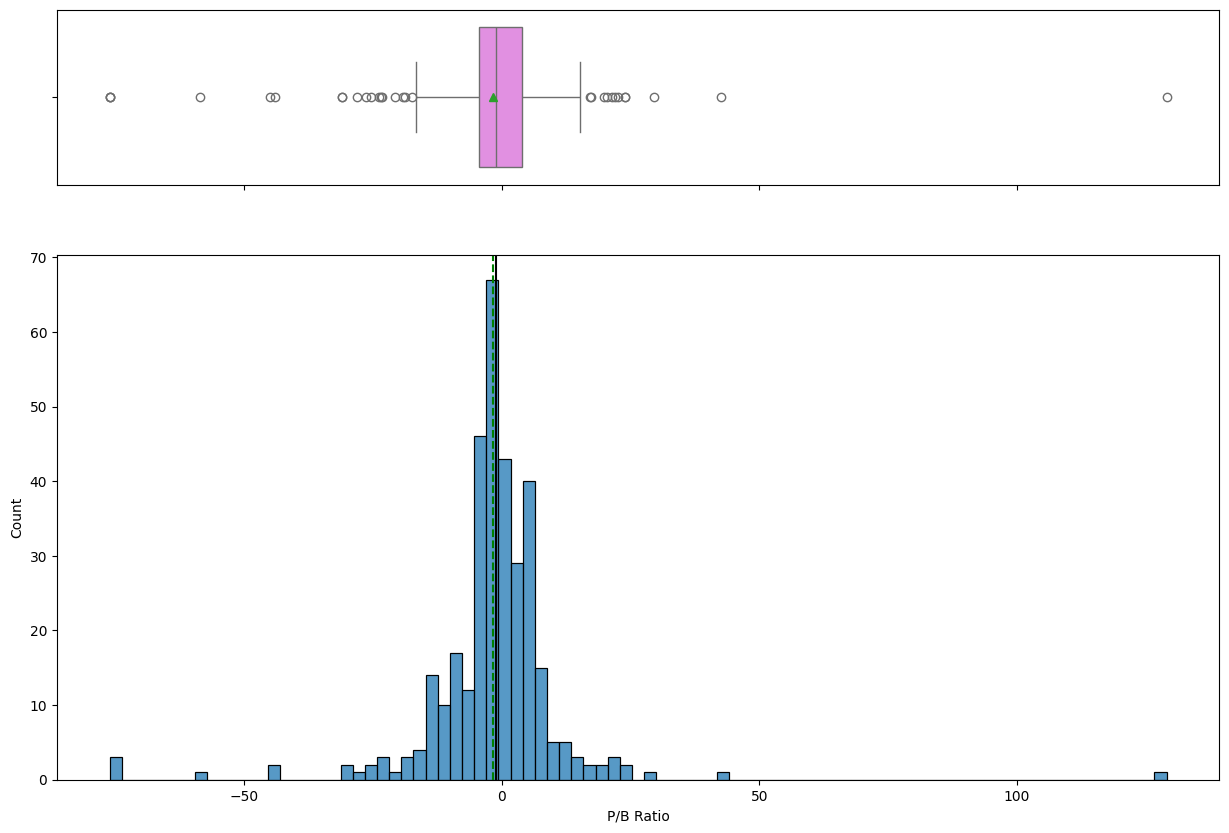

In [ ]:
histogram_boxplot(df, 'P/B Ratio')

## Bivariate

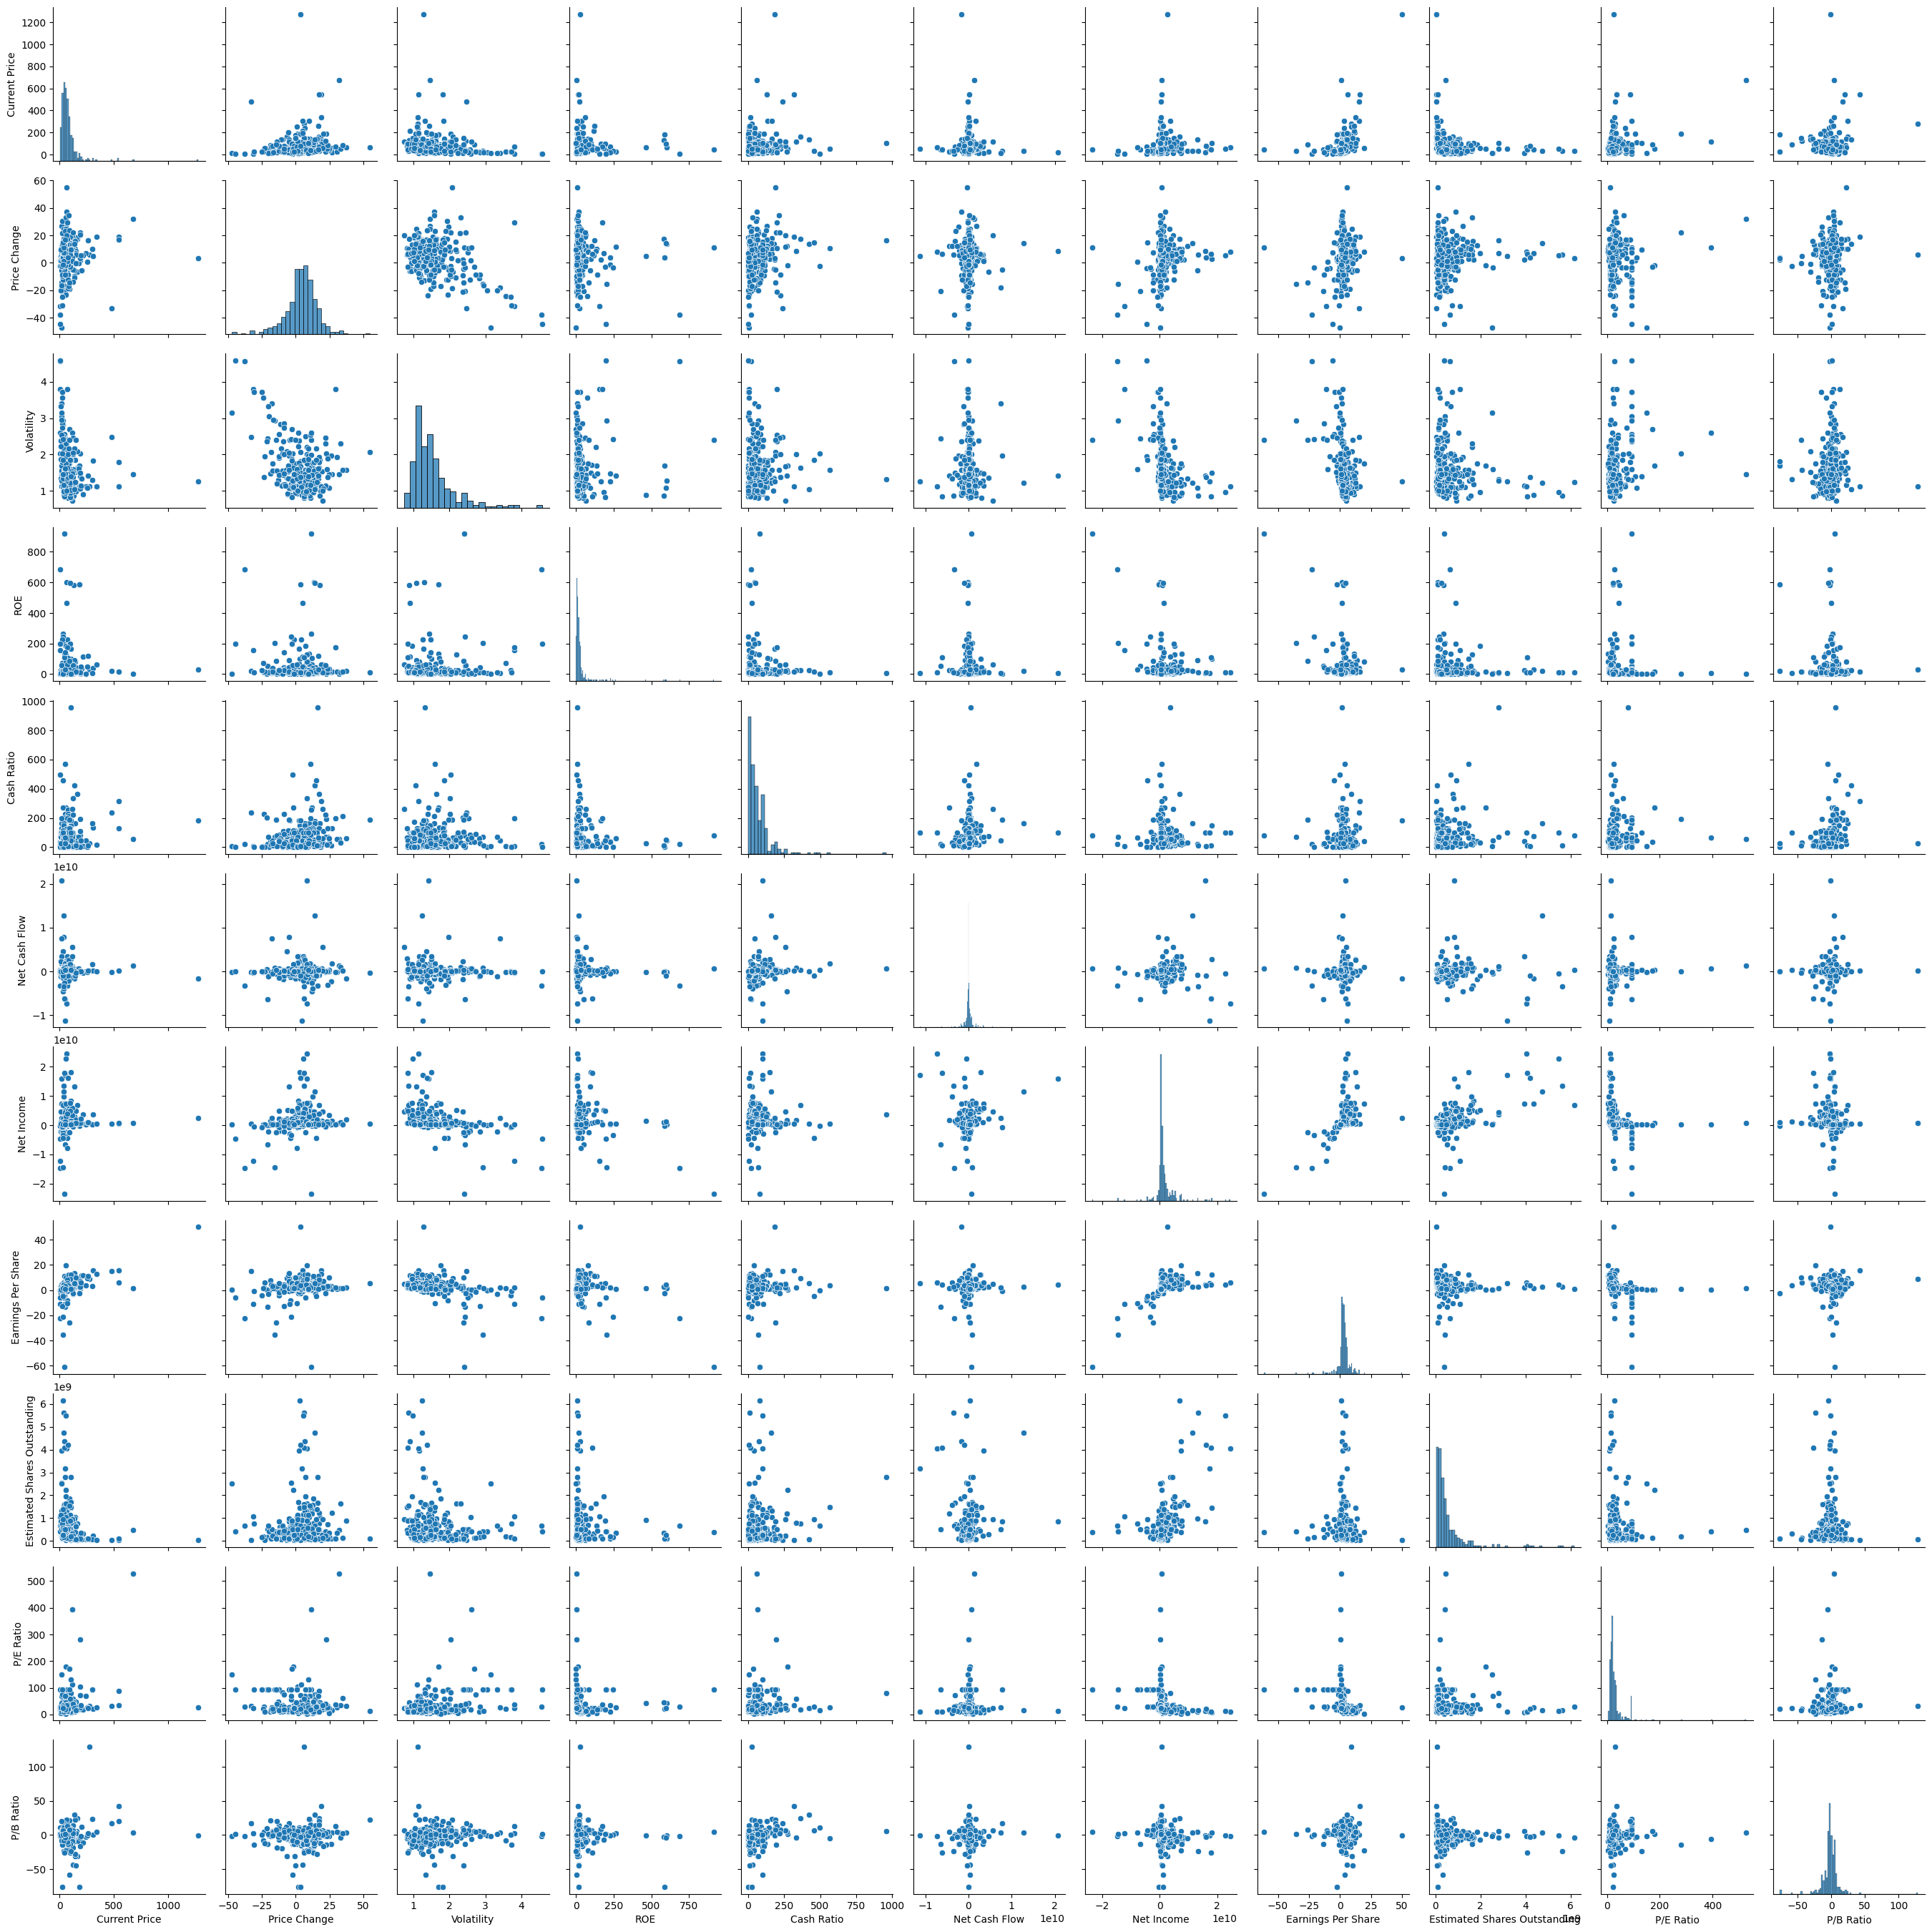

In [ ]:
sns.pairplot(df.select_dtypes(include='number'))

## Data Preprocessing

- Duplicate value check
- Missing value treatment
- Outlier check
- Feature engineering (if needed)
- Any other preprocessing steps (if needed)

In [41]:
# WE are going to remove the Outliers using the IQR method, but restricting it a little bit.
df=pd.read_csv('/content/drive/MyDrive/GREAT LEARNING/6. UNSUPERVISED LEARNING/Proyect/stock_data.csv')
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    Q1 = df[col].quantile(0.10)
    Q3 = df[col].quantile(0.90)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print(df.shape)
df.head()

(266, 15)


,Ticker Symbol,Security,GICS Sector,GICS Sub Industry,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio
0,AAL,American Airlines Group,Industrials,Airlines,42.350,10.000,1.687,135,51,-604000000,7610000000,11.390,668129938.500,3.718,-8.784
1,ABBV,AbbVie,Health Care,Pharmaceuticals,59.240,8.339,2.198,130,77,51000000,5144000000,3.150,1633015873.000,18.806,-8.750
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,44.910,11.301,1.274,21,67,938000000,4423000000,2.940,1504421769.000,15.276,-0.394
3,ADBE,Adobe Systems Inc,Information Technology,Application Software,93.940,13.977,1.358,9,180,-240840000,629551000,1.260,499643650.800,74.556,4.200
5,ADM,Archer-Daniels-Midland Co,Consumer Staples,Agricultural Products,36.680,-12.017,1.516,10,49,-189000000,1849000000,2.990,618394648.800,12.268,7.497


In [42]:
scaler = StandardScaler()
subset= scaler.fit_transform(df.select_dtypes(include='number'))
df_scaled=pd.DataFrame(subset,columns=df.select_dtypes(include='number').columns)
df_scaled.shape

(266, 11)

## EDA

- It is a good idea to explore the data once again after manipulating it.

In [43]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Current Price                 266 non-null    float64
 1   Price Change                  266 non-null    float64
 2   Volatility                    266 non-null    float64
 3   ROE                           266 non-null    float64
 4   Cash Ratio                    266 non-null    float64
 5   Net Cash Flow                 266 non-null    float64
 6   Net Income                    266 non-null    float64
 7   Earnings Per Share            266 non-null    float64
 8   Estimated Shares Outstanding  266 non-null    float64
 9   P/E Ratio                     266 non-null    float64
 10  P/B Ratio                     266 non-null    float64
dtypes: float64(11)
memory usage: 23.0 KB


In [44]:
df_scaled.describe()

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio
count,266.000,266.000,266.000,266.000,266.000,266.000,266.000,266.000,266.000,266.000,266.000
mean,0.000,-0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000
std,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002
min,-1.376,-3.328,-1.350,-0.884,-1.108,-4.383,-3.552,-4.066,-1.039,-1.132,-3.770
25%,-0.661,-0.466,-0.680,-0.547,-0.805,-0.181,-0.544,-0.554,-0.697,-0.577,-0.359
50%,-0.239,0.031,-0.208,-0.306,-0.251,0.040,-0.335,-0.093,-0.330,-0.346,0.042
75%,0.385,0.565,0.299,0.175,0.777,0.216,0.213,0.423,0.269,0.149,0.592
max,5.068,3.126,4.638,5.857,4.074,4.157,4.394,3.244,4.034,4.216,3.263


## K-means Clustering

Number of Clusters: 1 	Average Distortion: 2.9981324379932843
Number of Clusters: 2 	Average Distortion: 2.8220229213541135
Number of Clusters: 3 	Average Distortion: 2.678736302661997
Number of Clusters: 4 	Average Distortion: 2.545335686359666
Number of Clusters: 5 	Average Distortion: 2.489289823045292
Number of Clusters: 6 	Average Distortion: 2.3674876924958923
Number of Clusters: 7 	Average Distortion: 2.3484683506536683
Number of Clusters: 8 	Average Distortion: 2.2731230368070072
Number of Clusters: 9 	Average Distortion: 2.245925358223501
Number of Clusters: 10 	Average Distortion: 2.182002057690243
Number of Clusters: 11 	Average Distortion: 2.153218197499449
Number of Clusters: 12 	Average Distortion: 2.1260769597331537
Number of Clusters: 13 	Average Distortion: 2.0948506698289497
Number of Clusters: 14 	Average Distortion: 2.049992654666487


Text(0.5, 1.0, 'Selecting k with the Elbow Method')

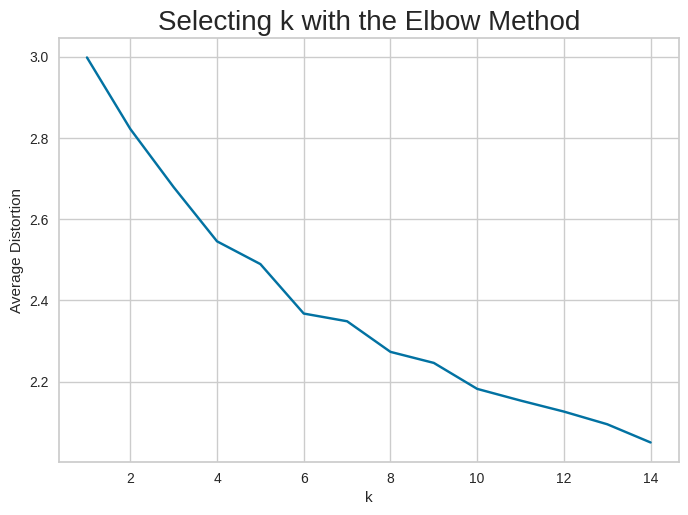

In [45]:
clusters = range(1, 15)
meanDistortions = []

for k in clusters:
    model = KMeans(n_clusters=k, random_state = 1)
    model.fit(df_scaled)
    prediction = model.predict(df_scaled)
    distortion = (
        sum(
            np.min(cdist(df_scaled, model.cluster_centers_, "euclidean"), axis=1)
        )
        / df_scaled.shape[0]
    )

    meanDistortions.append(distortion)

    print("Number of Clusters:", k, "\tAverage Distortion:", distortion)

plt.plot(clusters, meanDistortions, "bx-")
plt.xlabel("k")
plt.ylabel("Average Distortion")
plt.title("Selecting k with the Elbow Method", fontsize=20)

For n_clusters = 2, silhouette score is 0.25175212504284894
For n_clusters = 3, silhouette score is 0.20927002527976823
For n_clusters = 4, silhouette score is 0.16029918343587868
For n_clusters = 5, silhouette score is 0.10892128342777105
For n_clusters = 6, silhouette score is 0.1321518793807179
For n_clusters = 7, silhouette score is 0.10224204914538614
For n_clusters = 8, silhouette score is 0.14095842252935997
For n_clusters = 9, silhouette score is 0.13253816447179748
For n_clusters = 10, silhouette score is 0.11749296060392819
For n_clusters = 11, silhouette score is 0.11852695105249178
For n_clusters = 12, silhouette score is 0.09762653567242563
For n_clusters = 13, silhouette score is 0.12942672157664428
For n_clusters = 14, silhouette score is 0.11386935644520377


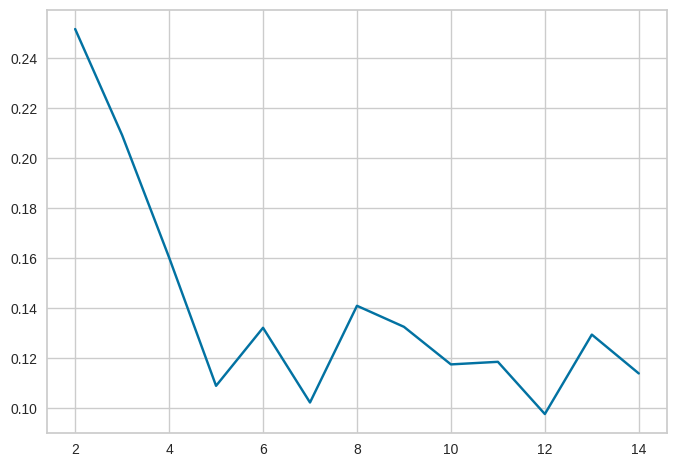

In [46]:
sil_score = []
cluster_list = list(range(2, 15))
for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state = 1)
    preds = clusterer.fit_predict((df_scaled))
    # centers = clusterer.cluster_centers_
    score = silhouette_score(df_scaled, preds)
    sil_score.append(score)
    print("For n_clusters = {}, silhouette score is {}".format(n_clusters, score))

plt.plot(cluster_list, sil_score)

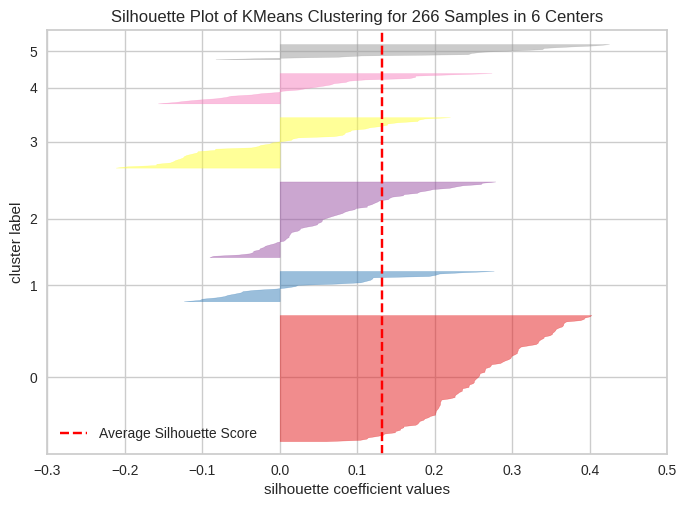

,count
K_means_segments,
0,101
2,61
3,41
1,25
4,25
5,13


In [47]:
# finding optimal no. of clusters with silhouette coefficients
n=6
visualizer = SilhouetteVisualizer(KMeans(n, random_state=1))
visualizer.fit(df_scaled)
visualizer.show()

kmeans = KMeans(n_clusters=n, random_state=1)
kmeans.fit(df_scaled)
# adding kmeans cluster labels to the original dataframe
df["K_means_segments"] = kmeans.labels_
df.value_counts('K_means_segments')

**Observations**

- 6 appears to be the appropriate number of clusters from the Silhoutte score and the elbow method

In [48]:
kmeans = KMeans(n_clusters=6, random_state=1)
kmeans.fit(df_scaled)

df["K_means_segments"] = kmeans.labels_

# Dropping the categorical column before proceeding with cluster profiling
cluster_profile = df.drop(['Ticker Symbol','Security','GICS Sector','GICS Sub Industry'], axis=1).groupby("K_means_segments").mean()

cluster_profile["count_in_each_segment"] = (df.groupby("K_means_segments")["Current Price"].count().values)

cluster_profile.style.highlight_max(color="lightgreen", axis=0)

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio,count_in_each_segment
K_means_segments,,,,,,,,,,,,
0,56.777049,2.443069,1.388531,18.623762,21.415842,-62437089.108911,723176435.643564,2.835149,274151505.849703,21.176683,-2.237378,101
1,82.388247,5.581825,1.323264,47.240000,54.160000,633560000.000000,5069320000.000000,6.299600,882119214.360000,14.955571,-1.807985,25
2,53.271475,6.350620,1.431847,16.770492,117.065574,146958098.360656,812755409.836066,2.510164,353909537.839836,23.697721,2.071709,61
3,143.593414,6.940138,1.286456,19.414634,46.634146,43861170.731707,1081000000.000000,5.806829,192318404.146098,32.032445,-7.010086,41
4,51.345432,10.821522,1.642431,11.960000,55.640000,-1005393360.000000,2011548240.000000,2.556000,989665059.148000,24.688026,-0.226096,25
5,38.775386,-13.708880,2.658027,18.153846,50.153846,-254421615.384615,-977527615.384615,-2.147692,402204588.269231,86.673270,0.970457,13


### Cluster profiling

**Cluster 0:**
Medium-sized companies with moderate financial performance. Negative cash flow but positive net income. Stable but low-growth companies.
**Observations:** 101

**Cluster 1:**
Highly profitable and stable companies. Strong cash flow, high ROE, and reasonable P/E ratios. Represents leaders in the sector. **Observations:** 25

**Cluster 2:**
Conservative companies with high liquidity. Low ROE, but stable financial results. Moderate P/E ratio. **Observations:** 61

**Cluster 3:**
Expensive companies with low profitability. High prices and P/E ratios, but limited financial results. Potential overvalued segment. **Observations:** 41

**Cluster 4:**
Companies facing financial difficulties. Negative net income and cash flow. Reflect speculative investments or restructuring cases. **Observations:** 25

**Cluster 5:**
Crisis companies. Lowest prices, negative growth, severe losses, and extremely high P/E ratios. High-risk segment. **Observations:** 13


## Hierarchical Clustering

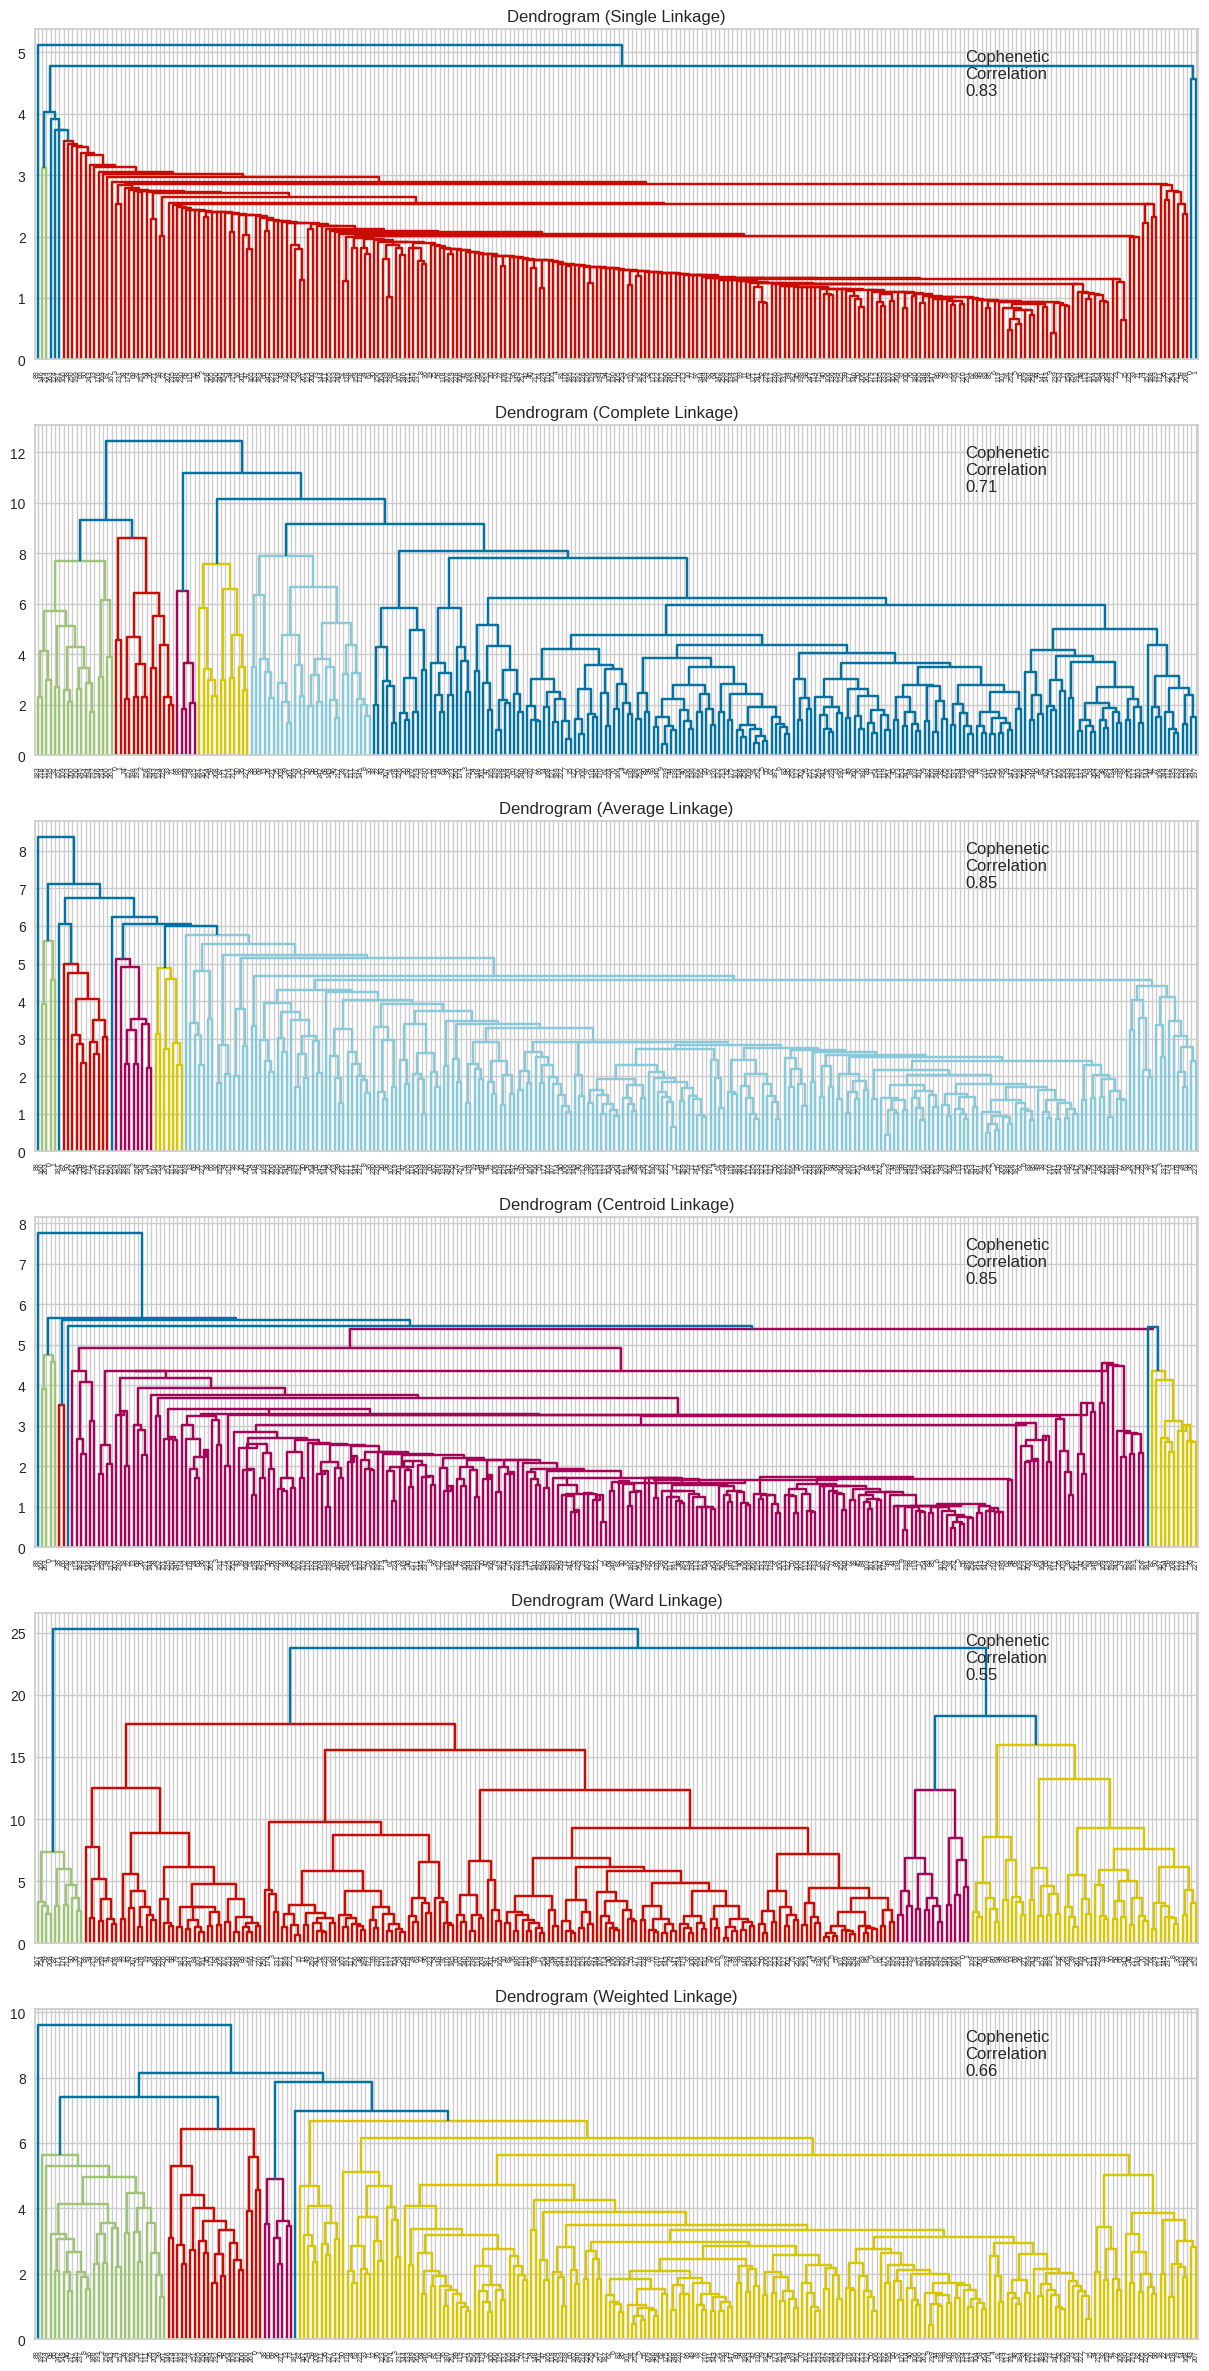

In [49]:
# list of linkage methods
linkage_methods = ["single", "complete", "average", "centroid", "ward", "weighted"]

# lists to save results of cophenetic correlation calculation
compare_cols = ["Linkage", "Cophenetic Coefficient"]

# to create a subplot image
fig, axs = plt.subplots(len(linkage_methods), 1, figsize=(15, 30))

# We will enumerate through the list of linkage methods above
# For each linkage method, we will plot the dendrogram and calculate the cophenetic correlation
for i, method in enumerate(linkage_methods):
    Z = linkage(df_scaled, metric="euclidean", method=method)

    dendrogram(Z, ax=axs[i])
    axs[i].set_title(f"Dendrogram ({method.capitalize()} Linkage)")

    coph_corr, coph_dist = cophenet(Z, pdist(df_scaled))
    axs[i].annotate(
        f"Cophenetic\nCorrelation\n{coph_corr:0.2f}",
        (0.80, 0.80),
        xycoords="axes fraction",
    )

**Observations**

- The cophenetic correlation is highest for average and centroid linkage methods.
- Despite that, after testing this method, all sotcks where place in the same custer. Given that we decided to use the complete linkage method wich gives more variability in the cluster selection.
- 6 appears to be the appropriate number of clusters from the dendrogram for complete linkage.

In [68]:
HCmodel = AgglomerativeClustering(n_clusters=6, linkage="complete")
HCmodel.fit(df_scaled)

df["HC_Clusters"] = HCmodel.labels_

# Dropping the categorical column before proceeding with cluster profiling
cluster_profile = df.drop(['Ticker Symbol','Security','GICS Sector','GICS Sub Industry','K_means_segments'], axis=1).groupby("HC_Clusters").mean()

cluster_profile["count_in_each_segment"] = (df.groupby("HC_Clusters")["Current Price"].count().values)

cluster_profile.style.highlight_max(color="lightgreen", axis=0)

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio,count_in_each_segment
HC_Clusters,,,,,,,,,,,,
0,64.725001,5.735192,1.314293,38.428571,64.785714,1428214285.714286,5291785714.285714,5.292857,1054609972.485714,15.611613,-3.631386,14
1,65.760682,4.094597,1.398469,16.867725,53.253968,-59166666.666667,803514116.402116,3.126561,279743228.520794,22.987897,-2.248761,189
2,55.607814,11.541764,1.541355,15.678571,67.571429,-361169071.428571,2265853785.714286,2.497857,1037807586.846429,24.605786,-1.347853,28
3,32.591667,-15.184988,2.788532,19.333333,50.416667,-273455916.666667,-1082661916.666667,-2.411667,412512160.166667,84.665650,1.308785,12
4,133.452010,7.198770,1.293849,54.555556,44.500000,-285289055.555556,2966552000.000000,8.491111,379218660.689444,16.487328,3.503854,18
5,206.724000,5.170551,1.281077,7.400000,68.600000,314039800.000000,290936000.000000,2.432000,143080180.580000,90.116343,1.913938,5


### CLustering profiling

**Cluster 0:**
MSolid and profitable companies. Strong ROE, positive cash flow, balanced valuation.
**Observations:** 14

**Cluster 1:**
Average companies. Largest segment. Stable but not outstanding performance. Slightly negative cash flow. **Observations:** 189

**Cluster 2:**
Liquid but less profitable companies. Negative cash flow and modest results. Slightly overvalued. **Observations:** 28

**Cluster 3:**
Companies in crisis. Severe losses and negative cash flow. Very high P/E ratio. **Observations:** 12

**Cluster 4:**
Premium, highly profitable companies. Strong ROE and positive results despite negative cash flow. Reasonable valuations. **Observations:** 18

**Cluster 5:**
Speculative, expensive companies. Very high price, low ROE, and modest results. Likely overvalued. **Observations:** 5


## K-means vs Hierarchical Clustering

You compare several things, like:
- Which clustering technique took less time for execution?
- Which clustering technique gave you more distinct clusters, or are they the same?
- How many observations are there in the similar clusters of both algorithms?
- How many clusters are obtained as the appropriate number of clusters from both algorithms?

You can also mention any differences or similarities you obtained in the cluster profiles from both the clustering techniques.



*   In this practical example, there seemed to be no clear difference in both techniches, even though in theory the Hierarchical clustering must take more time.
*   K-means Clustering offered clearer segmentation with more balanced groups, ideal for business strategies targeting specific segments. Hierarchical Clustering highlighted extremes but grouped most companies into a general cluster, which might reduce its actionable insights for operational use.

* The largest clusters in both methods represent the majority of standard-performing companies (101 vs 189). Both methods also identified crisis companies(13 vs 12)
*   We obtained 6 clsuters in both techniques





## Actionable Insights and Recommendations


*   **Focus on High-Performing Clusters (K-means Cluster 1, Hierarchical Cluster 4)**

  Prioritize these companies for recommending stable and profitable investments to clients.

  Develop specific investment strategies targeting their consistent returns and low risk.

*   **Monitor Crisis Clusters (K-means Cluster 5, Hierarchical Cluster 3):**

  Avoid suggesting these companies as investment options due to their severe financial risks.


*   **Target Average Performers (K-means Cluster 0, Hierarchical Cluster 1):**

  Identify potential growth opportunities within these stable but underperforming companies.

  Offer mid-term investment products leveraging their stability.


*   **Liquidity-Based Strategies (K-means Cluster 2, Hierarchical Cluster 2):**

  Position these companies as conservative investment options.

  Highlight their financial safety (high liquidity) as a selling point to risk-averse clients.

*   **Further Model Refinement**

  Continuously update and validate clustering models using fresh data to ensure segment relevance.
